# Deep Learning Assignment 1: Training Simple Neural Networks

Gabriel Wolf


In [2]:
# fetching data / importing libs
import sys
import torch
from torch import nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


torch.manual_seed(302) # reproducibility, said in the coding session it's necessary

X, y = fetch_california_housing(return_X_y=True)
X_train_tot, X_test, y_train_tot, y_test = train_test_split(X, y, test_size=0.25, random_state=302)

In [3]:
# picking computing unit since switching between laptop and desktop

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

## Part a: Tasks include the following
> Getting familiar with dataset, plotted them separately 
>
> Splitting Training data into effective training set and validation set
>
> Normalization of Data sets
>
> What's the difference between transform() and fit.transform()? - Answer Below

The main difference between transform() and fit.transform() lies in the fact that transform doesn't calculate new statistics (mean and std) for the dataset it is applied on. This must be archieved though by using the fit() function separately beforehand. So fit_transform() does calculate mean and std beforehand and then transforms the datasets in such a fashion:

$
x_{trans}=\frac{x-\mu}{\sigma}
$

It may be important to say that firstly, using the transform function without fitting before (calculating mean and std) seems useless, and secondly that fit() does NOT ALWAYS use mean / std (this only applies for the StandardScaler) 


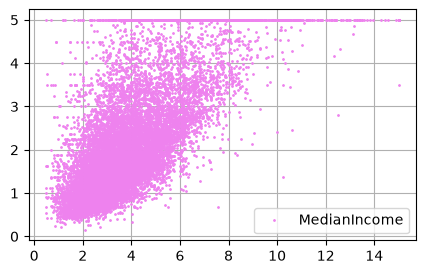

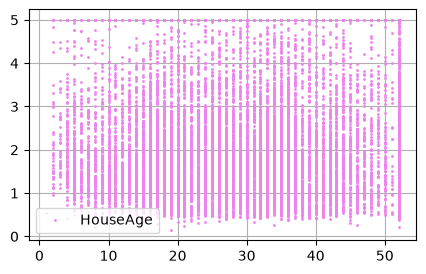

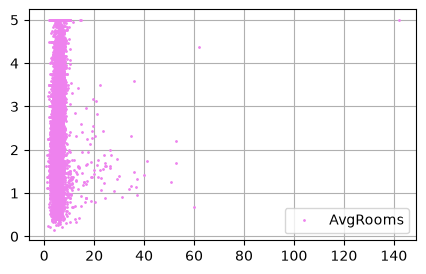

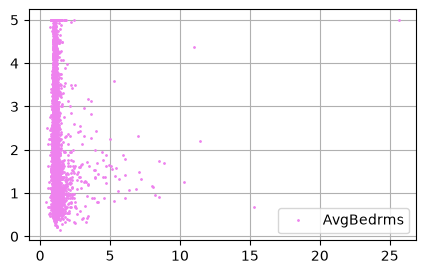

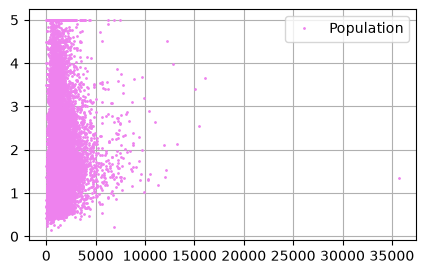

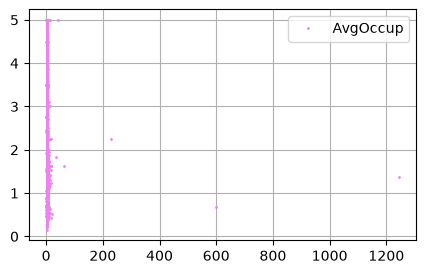

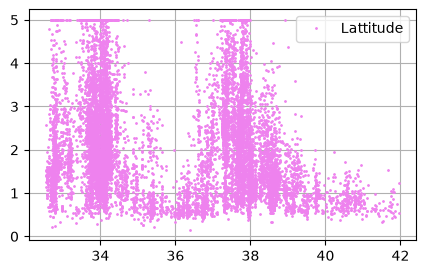

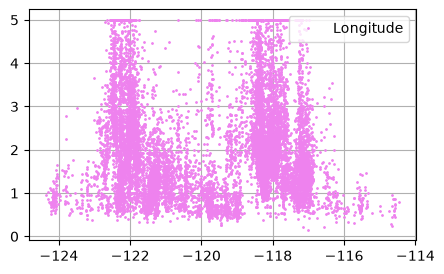

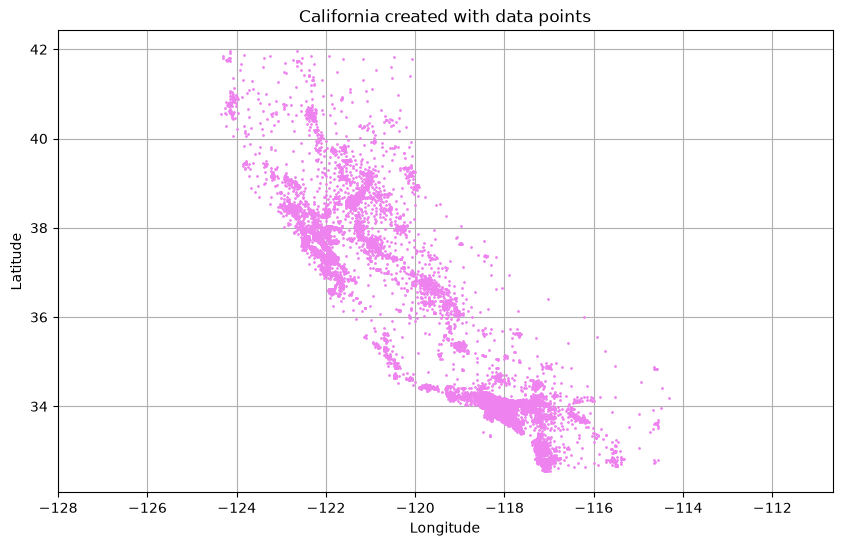

torch.Size([13158, 8]) torch.Size([2322, 8])


In [4]:
# Split Training Data into Training and Validation Sets first
X_train, X_val, y_train, y_val = train_test_split(X_train_tot, y_train_tot, test_size=0.15, random_state=302)
scaler = StandardScaler()
train_split = scaler.fit_transform(X_train)
val_split = scaler.transform(X_val)

# turning them into torch tensors for later training
X_train_split = torch.tensor(train_split, dtype=torch.float32).to(device)
y_train_split = torch.tensor(y_train, dtype=torch.float32).to(device)
X_val_split = torch.tensor(val_split, dtype=torch.float32).to(device)
y_val_split = torch.tensor(y_val, dtype=torch.float32).to(device)

# Getting familiar with the data, or what it's actually structured like
# X has Dim (20640, 8) and y has Dim (20640,) 
features = [
    "MedianIncome", "HouseAge", "AvgRooms", "AvgBedrms", "Population", "AvgOccup", "Lattitude", "Longitude"
]
for i in range(len(features)):
    plt.figure(figsize=(5, 3), facecolor='#FFFFFF')
    plt.plot(X_train[:, i], y_train, 'o', label=features[i], markersize=1, color='violet')
    plt.legend()
    plt.grid(True)
    plt.show()

# map of california with the data points
plt.figure(figsize=(10, 6), facecolor="#FFFFFF")
plt.plot(X[:, 7], X[:, 6], 'o', markersize=1, color='violet')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.axis('equal')
plt.title('California created with data points')
plt.grid(True)
plt.show()

print(X_train_split.shape, X_val_split.shape) # just checking

Heres a map of California as a reference: 

<img src="https://upload.wikimedia.org/wikipedia/commons/2/2e/Ca-regions.svg" width="400">

## Part b: Tasks include the following

> Design feedforward neural network for regression task
>
> Use SGD with proper mini batch size for minimizing loss func
>
> 10 differenct configs of hidden layer params and document them
>
> Table of params
>
> Explain design choices (output layer, loss func, batch size)


In [5]:
# adjusting data and separating the into batches with DataLoader
# data we want to use for training: X_train_split, y_train_split
# data we want to use for validation: X_val_split, y_val_split    <-- as a helpful not because i lost track of my datasets xD

batch_size = 16
train_dataset = torch.utils.data.TensorDataset(X_train_split, y_train_split)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True) # stuffs our data into x-batches and y-batches


### Used Model Parameters

| Parameter | Config |
|:--------------------|:------------------|
| **Architecture** | 8–64–64–64–1 | 
| **Hidden Layers** | 3 |
| **Activation Function** | ReLU |
| **Optimizer** | SGD |
| **Learning Rate** | 0.001 |
| **Batch Size** | 16 |
| **Epochs** | 100 |
| **Loss Function** | Mean Squared Error (MSE) |


In [6]:
# implementing model, loss func and optimizer

model = nn.Sequential(
    nn.Linear(8, 64), # input layer for 8 features to 64 neurons
    nn.ReLU(), # ReLU activation function since it is very common
    nn.Linear(64, 64), 
    nn.ReLU(),
    nn.Linear(64, 64), 
    nn.ReLU(),
    nn.Linear(64,1) 
).to(device) # onto to the GPU!
loss_fn = nn.MSELoss() # common mean squared err
optimizer = torch.optim.SGD(model.parameters(), lr=0.001) # stochastic gradient descent lr=0.001


# actual training loop for our feedforward neural network
val_losses = []
train_losses = [] # for later plotting

for epoch in range(100): #TRAINING LOOP
    model.train()
    batch_loss = 0
    
    # for each batch of data, we do forward pass, loss calculation, backward pass and optimizer step
    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device).reshape(-1, 1) # had some shape mismatch, this should fix it
        #first we do forward pass
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        # loss calculation and backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # keeping track of the loss for this batch
        batch_loss += loss.item() * X_batch.size(0)
        
        
    # now evaluating on validation set and other bookkeeping
    model.eval()
    with torch.no_grad():
        y_val_pred = model(X_val_split)
        val_loss = loss_fn(y_val_pred, y_val_split.reshape(-1, 1)) # also here reshape
        val_losses.append(val_loss.item()) # this one is easy because we dont have batches
        train_losses.append(batch_loss / len(train_loader.dataset)) # average loss over all batches
        
    


In [7]:
# Now in form of a function for better reusability and readability
def training(model, loss_fn, optimizer, train_loader, X_val_split=None, y_val_split=None, epochs=100):
    """General training loop for a PyTorch model, with validation loss tracking which can be plotted later

    Args:
        model (): PyTorch model to be trained
        loss_fn (): Loss function for the model (e.g.: nn.MSELoss())
        optimizer (): Optimizer for the model
        train_loader (): loader containing training data in batches, setup with torch.utils.data.Tensordataset() and DataLoader()
        X_val_split (): X values for validation set if given
        y_val_split (): y values for validation set if given
        epochs (int, optional): Number of epochs to train. Defaults to 100.

    Returns:
        train_losses: training losses, appended step by step for each epoch
        val_losses: valdation losses, appended step by step for each epoch (if none provided, will be empty)
    """
    val_needed = X_val_split is not None and y_val_split is not None
    if val_needed:
        X_val_split = X_val_split.to(device)
        y_val_split = y_val_split.to(device).reshape(-1, 1) 
    
    train_losses = []
    val_losses = []
    
    for epoch in range(epochs):
        model.train()
        batch_loss = 0
    
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device).reshape(-1, 1) 
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_loss += loss.item() * X_batch.size(0)
        
        
        model.eval()
        with torch.no_grad():
            if val_needed:
                y_val_pred = model(X_val_split)
                val_loss = loss_fn(y_val_pred, y_val_split.reshape(-1, 1)) 
                val_losses.append(val_loss.item()) 
        train_losses.append(batch_loss / len(train_loader.dataset))
            
    return train_losses, val_losses



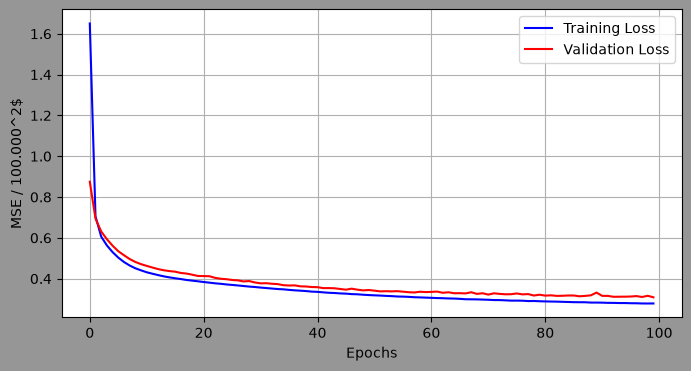

Last Training Loss: 0.278
Last Validation Loss: 0.309


In [8]:
# plotting training progress :)
plt.figure(figsize=(8, 4), facecolor="#969696")
plt.plot(train_losses, label='Training Loss', color='blue')
plt.plot(val_losses, label='Validation Loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('MSE / 100.000^2$')
plt.grid(True)
plt.legend()
plt.show()
print(f"Last Training Loss: {train_losses[-1]:.3f}")
print(f"Last Validation Loss: {val_losses[-1]:.3f}")
# 1000 epochs was way to much holy shit

Maybe the oscillating behaviour of the VL curve comes from the small batch size, leading to a little noise being introduced, this also can be observed even more intensely when lowering the batch size even more.

## Part c: Tasks include the following

> Perform final training on test and val set combined
>
> Make Scatterplot of predictions (x) vs true values (y)

In [9]:
# freshly transform the data, convert to tensors
# we want to train with X_train_tot and y_train_tot
# do the whole thing again with new dataset, less commentary :)

batch_size = 16
lr = 0.001

finscaler = StandardScaler()
X_train_tot_s = finscaler.fit_transform(X_train_tot)
X_test_s = finscaler.transform(X_test)  #only appplying statistics, no recalculation to prevent data leakage!! 

X_train_tot_tensor = torch.tensor(X_train_tot_s, dtype=torch.float32).to(device)
y_train_tot_tensor = torch.tensor(y_train_tot, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_s, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).to(device)
final_train_data = torch.utils.data.TensorDataset(X_train_tot_tensor, y_train_tot_tensor)
final_train_loader = DataLoader(final_train_data, batch_size=batch_size, shuffle=True)


final_model = nn.Sequential(
    nn.Linear(8, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
).to(device)

final_loss_fn = nn.MSELoss()
final_optimizer = torch.optim.SGD(final_model.parameters(), lr=lr)

# Final Training loop used with the function above
train_losses, _ = training(final_model, final_loss_fn, final_optimizer, final_train_loader, epochs=100)

# now evaluating
final_model.eval()
with torch.no_grad():
    y_test_pred = final_model(X_test_tensor)
    test_loss = final_loss_fn(y_test_pred, y_test_tensor.reshape(-1, 1))
    print(f"Test Loss: {test_loss.item()}")
    


Test Loss: 0.2906242907047272


Test Loss $\approx$ 0.29 $\newline$

When looking at the final values from the Training/Validation Session above from a different model, trained with the same hyperparameters we get: $\newline$

$
Last Training Loss \approx 0.278 \newline
Last Validation Loss \approx 0.309 \newline
$

Our final test loss for the final mdoel with $\approx$ 0.292 lies in between those values.

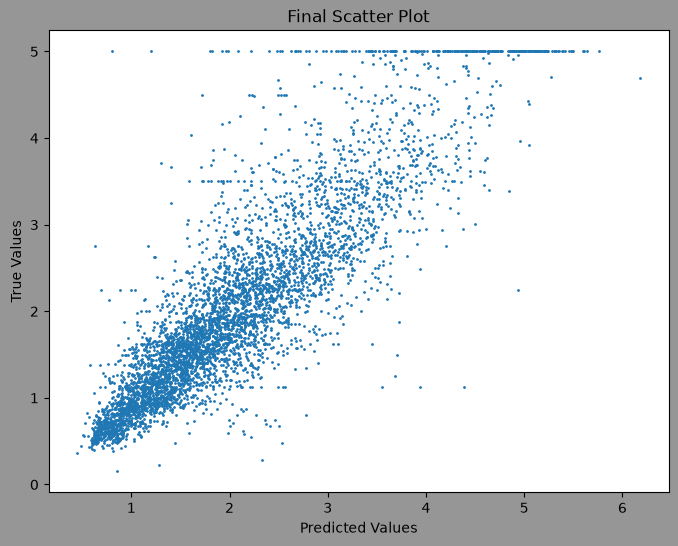

In [10]:
# Final Scatter plot comparing predictions (x) vs true values (y)

with torch.no_grad():
    plt.figure(figsize=(8, 6), facecolor="#969696")
    plt.scatter(y_test_pred.cpu().numpy(), y_test_tensor.cpu().numpy(), s=1)
    plt.xlabel('Predicted Values')
    plt.ylabel('True Values')
    plt.title('Final Scatter Plot')
    plt.show()

### Part d: Tasks include the following

> Explain what would have to change for the pipeline to be a binary classification problem (below or above 200.000$)
>
> Reimplement it as a binary classification task by using part c as a basis

So as a start the targets have to be changed into 1 and 0 if they're below of above 2(00000$) $\newline$ 
Then change the Loss function to a one fitting for a bin.-class.-task. (e.g. B-CrossEntropy) $\newline$ 


In [11]:
#redefining our targets to be 0 and 1
y_train_tot[y_train_tot < 2], y_test[y_test < 2] = 0, 0
y_train_tot[y_train_tot >= 2], y_test[y_test >= 2] = 1, 1
y_train_tot_tensor = torch.tensor(y_train_tot, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).to(device)
binary_train_data = torch.utils.data.TensorDataset(X_train_tot_tensor, y_train_tot_tensor)
binary_train_loader = DataLoader(binary_train_data, batch_size=batch_size, shuffle=True)


batch_size = 16
lr = 0.001

# now define a new model 


binary_model = nn.Sequential(
    nn.Linear(8, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 1),
    nn.Sigmoid() # since we have a BC problem, we want a final sigmoid activation (see Stackoverflow: https://stackoverflow.com/questions/75979632/pytorchs-nn-bcewithlogitsloss-behaves-totaly-differently-than-nn-bceloss)
).to(device)

bin_loss_fn = nn.BCELoss() # binary cross entropy loss for binary classification (recommended after a quick google)
bin_optimizer = torch.optim.SGD(binary_model.parameters(), lr=lr)

#training loop!
train_losses, _ = training(binary_model, bin_loss_fn, bin_optimizer, binary_train_loader, epochs=100)

# evaluation
binary_model.eval()
with torch.no_grad():
    y_test_pred = binary_model(X_test_tensor)
    bin_test_loss = bin_loss_fn(y_test_pred, y_test_tensor.reshape(-1, 1))
    print(f"Binary Test Loss: {bin_test_loss.item()}")

    
    # side note, i am deeply sorry for my variable management
    # throughout this notebook i overwrite them like 10000 times xD
    # personal reccomandation: change them


Binary Test Loss: 0.33106160163879395


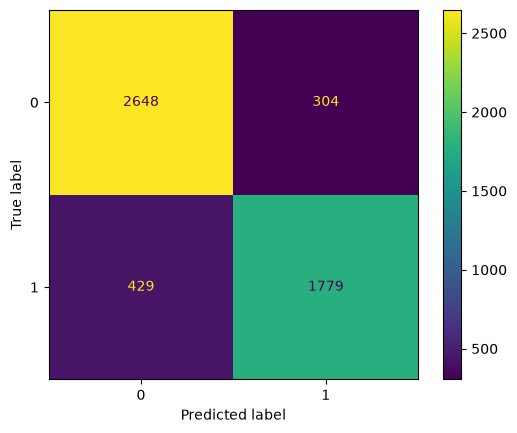

In [12]:
with torch.no_grad():   # looking at the confusion matrix bc i think a scatterplot would not be useful
    cm = confusion_matrix(y_test_tensor.cpu().numpy(), (y_test_pred.cpu().numpy() > 0.5).astype(int))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.show()